In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv(r"C:\Users\MAGIC\Downloads\hotel_bookings.csv.zip")
print(df.head())

          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Deposit   
1     

In [6]:
print("Dataset Shape:", df.shape)

Dataset Shape: (119390, 32)


In [7]:
print("Dataset Shape:", df.size)

Dataset Shape: 3820480


In [9]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')


In [12]:
print("Data Types:")
print(df.dtypes)

Data Types:
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                 

In [13]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340


In [14]:
df['children'] = df['children'].fillna(df['children'].median())


In [15]:
df['country'] = df['country'].fillna(df['country'].mode()[0])

In [17]:
df = df.drop(['agent', 'company'],axis=1)

In [19]:
print(df.isnull().sum())

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

In [20]:
encoded_df = pd.get_dummies(
    df,
    columns=['hotel', 'meal', 'market_segment'],
    dtype=int
)
print(encoded_df.head())

   is_canceled  lead_time  arrival_date_year arrival_date_month  \
0            0        342               2015               July   
1            0        737               2015               July   
2            0          7               2015               July   
3            0         13               2015               July   
4            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  children  ...  \
0                        0                     0       2       0.0  ...   
1                        0                     0       2       0.0  ...   
2                      

In [21]:
num_cols = [
    'lead_time', 'adr', 'stays_in_week_nights','adults','total_of_special_requests']
print(df[num_cols].head())

   lead_time   adr  stays_in_week_nights  adults  total_of_special_requests
0        342   0.0                     0       2                          0
1        737   0.0                     0       2                          0
2          7  75.0                     1       1                          0
3         13  75.0                     1       1                          0
4         14  98.0                     2       2                          1


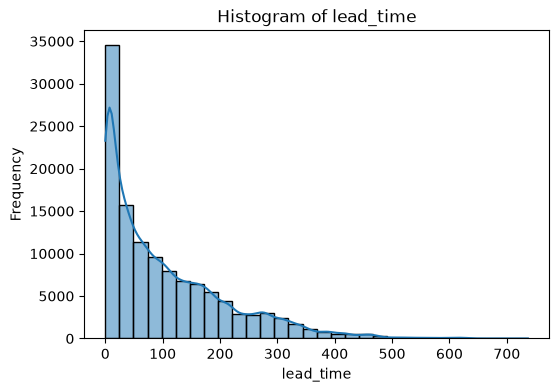

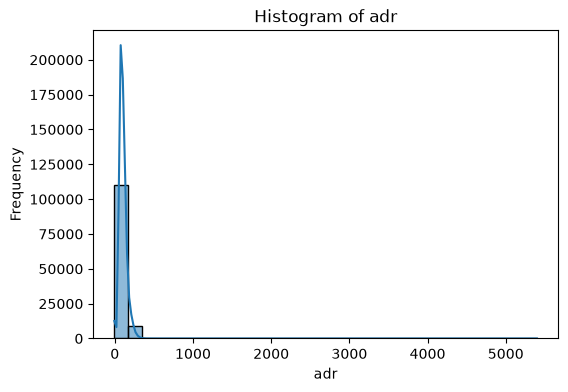

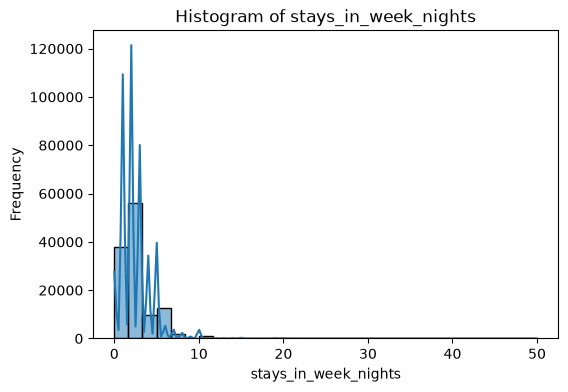

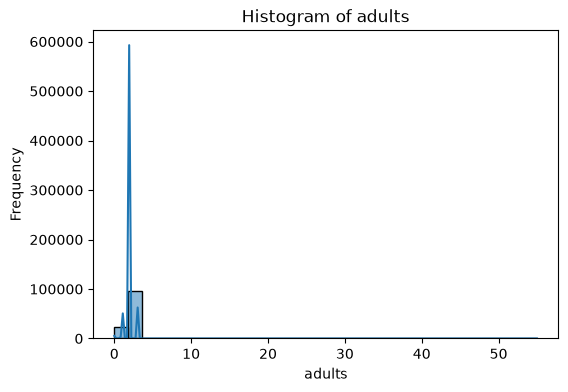

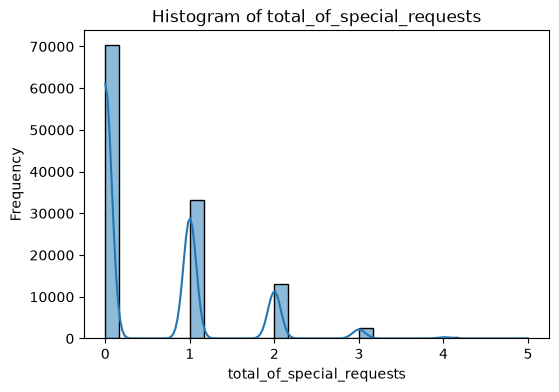

In [22]:
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title("Histogram of " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

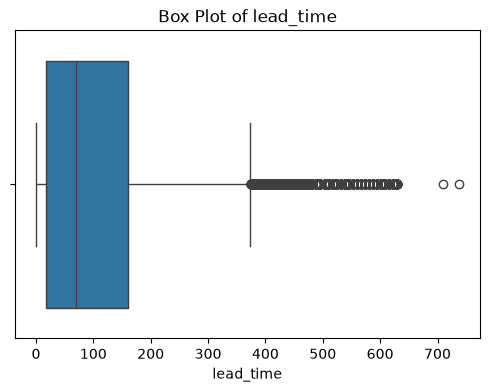

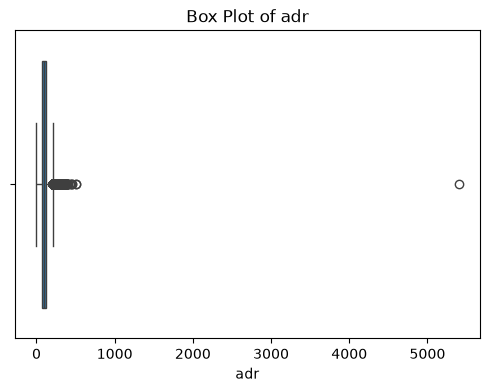

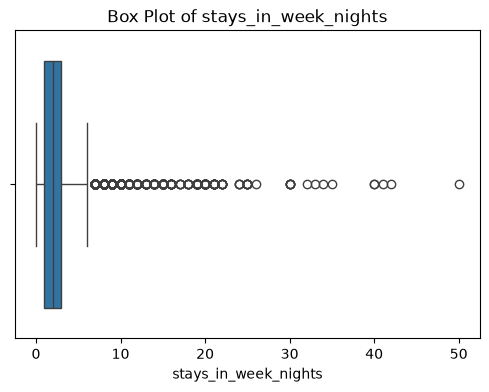

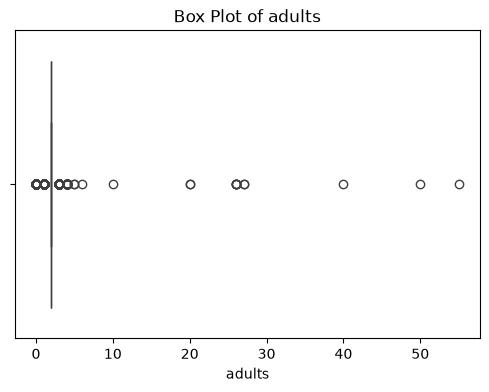

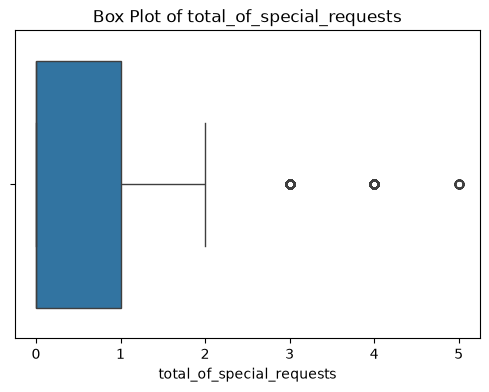

In [23]:
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title("Box Plot of " + col)
    plt.xlabel(col)
    plt.show()

In [24]:
for col in num_cols:
    print("\nColumn:", col)
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


Column: lead_time
Skewness: 1.3465498727254264
Kurtosis: 1.696448848558545

Column: adr
Skewness: 10.53021398218952
Kurtosis: 1013.1898508588172

Column: stays_in_week_nights
Skewness: 2.8622492420671244
Kurtosis: 24.284554815417337

Column: adults
Skewness: 18.317804759206098
Kurtosis: 1352.1151163093687

Column: total_of_special_requests
Skewness: 1.3491893774222594
Kurtosis: 1.4925648106220506


In [26]:
for col in num_cols:
 skew_value = df[col].skew()
print("\nColumn:", col)
if skew_value > 0.5:
  print("Positively Skewed")
elif skew_value < -0.5:
  print("Negatively Skewed")
else:
  print("Approximately Symmetric")


Column: total_of_special_requests
Positively Skewed
